# 04 - Payment amounts

**Question:** how does the generator decide the USD amount of a payment?

Works on the `feat` view (clean data + features from `03_features`) through `src/eda.py`. All analysis uses **normal payments only** (9,992,994 rows); anomalies are covered in `02_anomaly_types`. Charts are saved to `reports/figures/` with the prefix `M`.

Main tool: `usd_amount_log10` (log10 of the amount). On a log scale "10x larger" is "+1", which turns multiplicative rules into simple additions.

## 0. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Works whether Jupyter was started in the project root or in notebooks/
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
assert (ROOT / "src").exists(), f"Project root not found from {Path.cwd()}"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import eda

eda.connect()  # in-memory DuckDB in UTC with views tx (clean) and feat (clean + features). If RAM runs out: eda.connect(memory_limit="3GB")
eda.require_columns("feat", ["party_pair", "sender_country", "receiver_country", "usd_amount_log10", "usd_amount_magnitude", "usd_amount_is_whole"])
q, save = eda.q, eda.save

# Normal payments only: the rules in this notebook describe regular traffic (anomalies are in 02_anomaly_types)
eda.con.execute("CREATE OR REPLACE VIEW normal AS SELECT * FROM feat WHERE is_anomaly = 0")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

tx     10,000,000 rows x 21 columns
feat   10,000,000 rows x 40 columns
DuckDB 2.0.0 | time zone UTC


## 1. Sanity check

In [2]:
checks = q("""
    SELECT count(*)                                AS rows,
           count(*) FILTER (WHERE is_anomaly = 0)  AS normal_rows,
           min(epoch_seconds)                      AS first_payment,
           max(epoch_seconds)                      AS last_payment
    FROM feat
""")
assert checks.loc[0, "rows"] == 10_000_000
assert checks.loc[0, "normal_rows"] == 9_992_994
checks

,rows,normal_rows,first_payment,last_payment
0,10000000,9992994,2023-04-30 11:22:26+00:00,2023-07-31 09:56:01+00:00


## Hypotheses (written before testing)

| ID | Hypothesis | Test |
|---|---|---|
| H-M1 | Amounts follow a log-normal distribution (a bell curve on a log scale) | Shape of log10(amount): skewness and kurtosis per party pair (M1) |
| H-M2 | Businesses send and receive larger amounts than consumers | Mean log10(amount) by party pair; is the effect additive? Does it hold within the same sender? (M2) |
| H-M3 | Each sender account has its own typical amount level | Share of variance explained by the sender; spread of sender means vs pure noise (M3) |
| H-M4 | Country matters: payments from "richer" countries are larger | Level by sender country and by receiver country, party mix removed (M4) |
| H-M5 | The payment currency has its own effect on the amount | Currency levels before and after removing the sender-country level (M5) |
| H-M6 | People pay round amounts (1,000, 5,000 ...) | Share of whole-dollar amounts by currency, sender type, country and size; which round numbers (M6) |
| H-M7 | Larger payments use longer routes | Level by transaction type and number of banks, country and party mix removed (M7) |

## M1. Shape of the amount distribution (H-M1)
If amounts are log-normal, `log10(amount)` is a normal bell curve: skewness ≈ 0 and excess kurtosis ≈ 0.

In [3]:
m1 = q("""
    SELECT party_pair,
           count(*)                              AS n,
           median(usd_amount)                    AS median_usd,
           avg(usd_amount_log10)                 AS mean_log10,
           stddev(usd_amount_log10)              AS sd_log10,
           skewness(usd_amount_log10)            AS skewness,
           kurtosis(usd_amount_log10)            AS excess_kurtosis
    FROM normal
    GROUP BY 1
    ORDER BY 1
""")
m1.round(3)  # excess kurtosis is 0 for a perfect normal curve

,party_pair,n,median_usd,mean_log10,sd_log10,skewness,excess_kurtosis
0,B2B,2269885,22883.000,4.342,0.992,-0.119,0.082
1,B2C,5600965,3117.510,3.472,0.992,-0.120,0.086
2,C2B,609762,3236.315,3.486,0.992,-0.117,0.083
3,C2C,1512382,463.650,2.633,0.996,-0.131,0.149


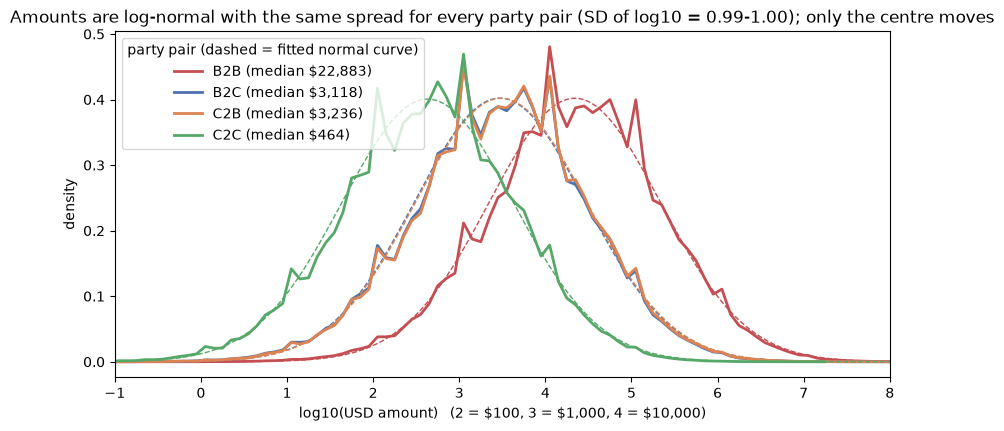

In [4]:
hist = q("""
    SELECT party_pair, floor(usd_amount_log10 * 10) / 10 AS bin, count(*) AS n
    FROM normal
    GROUP BY 1, 2
""")
colors = {"C2C": "#55A868", "B2C": "#4C72B0", "C2B": "#DD8452", "B2B": "#C44E52"}
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.linspace(-2, 9, 400)
for _, r in m1.iterrows():
    h = hist[hist.party_pair == r.party_pair].sort_values("bin")
    ax.plot(h.bin + 0.05, h.n / h.n.sum() / 0.1, color=colors[r.party_pair], lw=2, label=f"{r.party_pair} (median \\${r.median_usd:,.0f})")
    pdf = np.exp(-0.5 * ((x - r.mean_log10) / r.sd_log10) ** 2) / (r.sd_log10 * np.sqrt(2 * np.pi))
    ax.plot(x, pdf, color=colors[r.party_pair], lw=1, ls="--")
ax.set_xlim(-1, 8)
ax.set_xlabel("log10(USD amount)   (2 = \\$100, 3 = \\$1,000, 4 = \\$10,000)")
ax.set_ylabel("density")
ax.legend(title="party pair (dashed = fitted normal curve)")
ax.set_title(f"Amounts are log-normal with the same spread for every party pair (SD of log10 = "
             f"{m1.sd_log10.min():.2f}-{m1.sd_log10.max():.2f}); only the centre moves")
save(fig, "M1_amount_lognormal")
plt.show()

## M2. Party types shift the amount level (H-M2)
If the generator adds one effect for a business sender and one for a business receiver, then on the log scale
`B2B = C2C + (B2C - C2C) + (C2B - C2C)`. A second check removes each sender's own level, so only the receiver type can explain what is left.

In [5]:
lv = m1.set_index("party_pair")["mean_log10"]
sender_b = lv["B2C"] - lv["C2C"]       # effect of a business sender (receiver fixed = consumer)
receiver_b = lv["C2B"] - lv["C2C"]     # effect of a business receiver (sender fixed = consumer)
m2 = pd.DataFrame({
    "effect (log10)": [sender_b, receiver_b, lv["B2B"] - lv["C2C"], sender_b + receiver_b],
    "multiplier": [10 ** sender_b, 10 ** receiver_b, 10 ** (lv["B2B"] - lv["C2C"]), 10 ** (sender_b + receiver_b)],
}, index=["business sender (B2C vs C2C)", "business receiver (C2B vs C2C)",
          "both, observed (B2B vs C2C)", "both, predicted if additive"])
m2.round(3)

,effect (log10),multiplier
business sender (B2C vs C2C),0.839,6.902
business receiver (C2B vs C2C),0.853,7.134
"both, observed (B2B vs C2C)",1.709,51.191
"both, predicted if additive",1.692,49.239


In [6]:
# Within the same sender: deviation of each payment from its sender's own mean, by receiver type
m2_within = q("""
    WITH s AS (
        SELECT ordering_account, avg(usd_amount_log10) AS sender_mean, count(*) AS n
        FROM normal GROUP BY 1
    )
    SELECT ordering_type AS sender_type, beneficiary_type AS receiver_type,
           count(*)                                 AS n,
           avg(usd_amount_log10 - s.sender_mean)    AS mean_dev_from_own_sender_mean
    FROM normal JOIN s USING (ordering_account)
    WHERE s.n >= 5
    GROUP BY 1, 2
    ORDER BY 1, 2
""")
gap = m2_within.groupby("sender_type").mean_dev_from_own_sender_mean.agg(lambda s: s.iloc[0] - s.iloc[1])
print("Business-receiver effect within the same sender (log10):", gap.round(3).to_dict())
m2_within.round(3)

Business-receiver effect within the same sender (log10): {'B': 0.832, 'C': 0.804}


,sender_type,receiver_type,n,mean_dev_from_own_sender_mean
0,B,B,2219931,0.592
1,B,C,5478731,-0.240
2,C,B,534631,0.573
3,C,C,1327738,-0.231


## M3. Each sender has its own amount level (H-M3)
Share of the variance of `log10(amount)` explained by the sender account (senders with at least 5 payments), and the spread of sender means for senders with at least 50 payments, compared with the spread pure noise would produce.

In [7]:
m3 = q("""
    WITH s AS (
        SELECT ordering_account, count(*) AS n, avg(usd_amount_log10) AS m
        FROM normal GROUP BY 1
    ),
    x AS (
        SELECT usd_amount_log10 AS l, s.m, s.n FROM normal JOIN s USING (ordering_account) WHERE s.n >= 5
    )
    SELECT count(*)                          AS rows,
           var_pop(l)                        AS total_variance,
           avg((l - m) * (l - m))            AS within_sender_variance,
           1 - avg((l - m) * (l - m)) / var_pop(l) AS share_explained_by_sender
    FROM x
""")
m3_spread = q("""
    WITH s AS (
        SELECT ordering_account, any_value(ordering_type) AS sender_type, count(*) AS n,
               avg(usd_amount_log10) AS m, var_pop(usd_amount_log10) AS v
        FROM normal GROUP BY 1
    )
    SELECT sender_type, count(*) AS senders_with_50plus,
           stddev(m)                 AS observed_sd_of_sender_means,
           sqrt(avg(v / n))          AS sd_expected_from_noise_only
    FROM s WHERE n >= 50
    GROUP BY 1 ORDER BY 1
""")
display(m3.round(4))
m3_spread.round(3)

,rows,total_variance,within_sender_variance,share_explained_by_sender
0,9561031,1.2155,0.9093,0.252


,sender_type,senders_with_50plus,observed_sd_of_sender_means,sd_expected_from_noise_only
0,B,22497,0.444,0.090
1,C,6381,0.378,0.099


## M4. Country: sender vs receiver (H-M4)
Each payment's party-pair mean is subtracted first (the residual), so the country levels are not just a different B/C mix. Countries with at least 20,000 payments.

In [8]:
m4 = q("""
    WITH pm AS (SELECT party_pair, avg(usd_amount_log10) AS pm FROM normal GROUP BY 1),
    r AS (SELECT sender_country, receiver_country, usd_amount_log10 - pm.pm AS res FROM normal JOIN pm USING (party_pair))
    SELECT 'sender country' AS side, sender_country AS country, count(*) AS n, avg(res) AS amount_level FROM r GROUP BY 2
    UNION ALL
    SELECT 'receiver country', receiver_country, count(*), avg(res) FROM r GROUP BY 2
""")
m4 = m4[m4.n >= 20_000]
spread = m4.groupby("side")["amount_level"].agg(countries="size", sd_of_country_levels="std", lowest="min", highest="max")
spread.round(3)  # log10 units: 0.3 = 2x, 1 = 10x

,countries,sd_of_country_levels,lowest,highest
side,,,,
receiver country,59,0.100,-0.708,0.085
sender country,62,0.473,-1.385,0.884


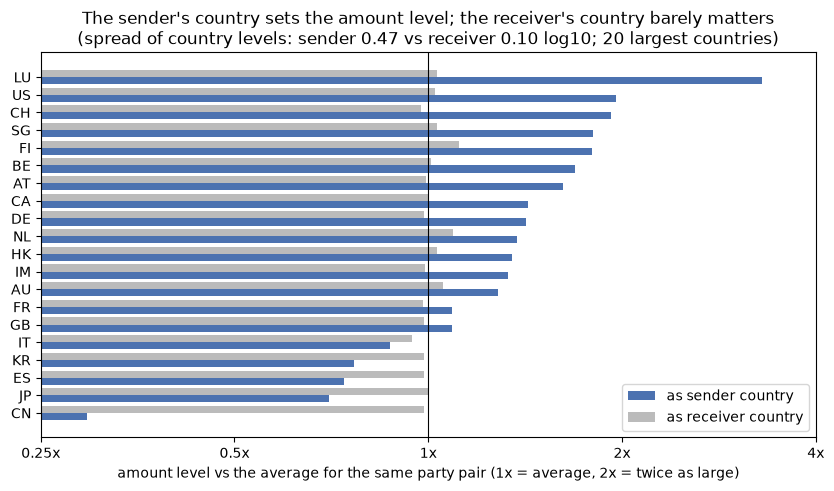

In [9]:
top = (m4[m4.side == "sender country"].nlargest(20, "n").country.tolist())
s = m4[m4.side == "sender country"].set_index("country").loc[top, "amount_level"]
r = m4[m4.side == "receiver country"].set_index("country").reindex(top)["amount_level"]
order = s.sort_values().index
fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(order))
ax.barh(y - 0.2, 10 ** s[order], height=0.4, color="#4C72B0", label="as sender country")
ax.barh(y + 0.2, 10 ** r[order], height=0.4, color="#BBBBBB", label="as receiver country")
ax.axvline(1, color="black", lw=0.8)
ax.set_yticks(y)
ax.set_yticklabels(order)
ax.set_xscale("log")
ax.set_xticks([0.25, 0.5, 1, 2, 4])
ax.set_xticklabels(["0.25x", "0.5x", "1x", "2x", "4x"])
ax.minorticks_off()
ax.set_xlabel("amount level vs the average for the same party pair (1x = average, 2x = twice as large)")
ax.legend(loc="lower right")
sd = spread["sd_of_country_levels"]
ax.set_title(f"The sender's country sets the amount level; the receiver's country barely matters\n"
             f"(spread of country levels: sender {sd['sender country']:.2f} vs receiver {sd['receiver country']:.2f} log10; 20 largest countries)")
save(fig, "M4_amount_by_country")
plt.show()

## M5. Does the currency matter on its own? (H-M5)
Raw medians differ a lot between currencies. Test: remove the party-pair mean and the sender-country level, then see what is left per currency. "Home currency" = the currency used most by senders from that country.

In [10]:
m5 = q("""
    WITH pm AS (SELECT party_pair, avg(usd_amount_log10) AS pm FROM normal GROUP BY 1),
    r AS (SELECT sender_country, currency_code, usd_amount_log10 - pm.pm AS res FROM normal JOIN pm USING (party_pair)),
    c AS (SELECT sender_country, avg(res) AS country_level FROM r GROUP BY 1),
    home AS (SELECT sender_country, arg_max(currency_code, n) AS home_currency
             FROM (SELECT sender_country, currency_code, count(*) AS n FROM normal GROUP BY 1, 2) GROUP BY 1)
    SELECT r.currency_code, count(*) AS n,
           avg(res)                                       AS level_before,
           avg(res - c.country_level)                     AS level_after_sender_country,
           avg((r.currency_code = h.home_currency)::INT)  AS share_home_currency
    FROM r JOIN c USING (sender_country) JOIN home h USING (sender_country)
    GROUP BY 1
""")
m5 = m5[m5.n >= 20_000]
print(f"Currencies with 20,000+ payments: {len(m5)}")
print(f"Spread of currency levels BEFORE removing the sender country: {m5.level_before.std():.3f} log10")
print(f"Spread of currency levels AFTER  removing the sender country: {m5.level_after_sender_country.std():.3f} log10")
m5.sort_values("n", ascending=False).head(12).round(3)

Currencies with 20,000+ payments: 47
Spread of currency levels BEFORE removing the sender country: 0.435 log10
Spread of currency levels AFTER  removing the sender country: 0.002 log10


,currency_code,n,level_before,level_after_sender_country,share_home_currency
13,EUR,3197037,0.095,-0.000,0.855
110,USD,1702039,0.228,-0.000,0.864
119,GBP,873422,0.001,0.000,0.911
31,CHF,803526,0.288,-0.000,0.928
120,SGD,367461,0.240,0.001,0.936
111,CNY,324396,-0.479,-0.000,0.907
121,HKD,197371,0.124,0.002,0.938
93,JPY,184136,-0.143,-0.000,0.926
78,AUD,166788,0.087,0.001,0.938
47,CAD,111069,0.147,0.000,0.943


In [11]:
m5_home = q("""
    WITH pm AS (SELECT party_pair, avg(usd_amount_log10) AS pm FROM normal GROUP BY 1),
    r AS (SELECT sender_country, currency_code, usd_amount_log10 - pm.pm AS res FROM normal JOIN pm USING (party_pair)),
    c AS (SELECT sender_country, avg(res) AS country_level FROM r GROUP BY 1),
    home AS (SELECT sender_country, arg_max(currency_code, n) AS home_currency
             FROM (SELECT sender_country, currency_code, count(*) AS n FROM normal GROUP BY 1, 2) GROUP BY 1)
    SELECT r.currency_code = h.home_currency AS paid_in_home_currency_of_sender,
           count(*) AS n,
           avg(res - c.country_level) AS level_after_sender_country
    FROM r JOIN c USING (sender_country) JOIN home h USING (sender_country)
    GROUP BY 1
""")
m5_home.round(3)

,paid_in_home_currency_of_sender,n,level_after_sender_country
0,False,1054608,-0.002
1,True,8938386,0.000


## M6. Round amounts (H-M6)
A whole-dollar amount (no cents) is a sign the payer typed a round number. Converting from another currency to USD creates random cents, so rounding can only be seen in **USD payments**.

In [12]:
m6 = q("""
    SELECT currency_code = 'USD'                                    AS is_usd,
           ordering_type                                           AS sender_type,
           sender_country = 'US'                                   AS sender_in_us,
           count(*)                                                AS n,
           100 * avg(usd_amount_is_whole::INT)                     AS pct_whole_dollars,
           100 * avg((usd_amount % 1000 = 0)::INT)                 AS pct_whole_thousands
    FROM normal
    GROUP BY 1, 2, 3
    ORDER BY 1, 2, 3
""")
m6.round(1)

,is_usd,sender_type,sender_in_us,n,pct_whole_dollars,pct_whole_thousands
0,False,B,False,6388148,1.0,0.0
1,False,B,True,121109,0.9,0.0
2,False,C,False,1752919,1.0,0.0
3,False,C,True,28779,0.9,0.0
4,True,B,False,208276,38.5,10.5
5,True,B,True,1153317,38.7,12.7
6,True,C,False,62088,38.0,5.8
7,True,C,True,278358,38.4,7.7


In [13]:
m6_size = q("""
    SELECT usd_amount_magnitude AS magnitude,
           count(*) AS n,
           100 * avg(usd_amount_is_whole::INT) AS pct_whole_dollars
    FROM normal
    WHERE currency_code = 'USD' AND usd_amount >= 1
    GROUP BY 1 ORDER BY 1
""")
m6_size = m6_size[m6_size.n >= 1000].round(1)   # sizes with fewer than 1,000 USD payments are too small to compare
m6_size  # magnitude 3 = $1,000-$9,999.99

,magnitude,n,pct_whole_dollars
0,0,8607,40.5
1,1,71934,40.8
2,2,299830,39.8
3,3,584878,38.5
4,4,509039,38.0
5,5,194073,38.1
6,6,31193,39.2
7,7,1950,37.6


In [14]:
# Which round numbers? Significant digits of whole-dollar USD amounts, and the leading digit of 1-digit amounts
m6_digits = q("""
    WITH w AS (
        SELECT ordering_type AS sender_type, usd_amount::BIGINT::VARCHAR AS a
        FROM normal
        WHERE currency_code = 'USD' AND usd_amount_is_whole AND usd_amount >= 1
    )
    SELECT sender_type, least(length(rtrim(a, '0')), 6) AS significant_digits, count(*) AS n
    FROM w GROUP BY 1, 2
""")
m6_sig = (m6_digits.pivot(index="significant_digits", columns="sender_type", values="n")
                   .pipe(lambda t: (t / t.sum() * 100).round(1)))
m6_lead = q("""
    WITH w AS (SELECT usd_amount::BIGINT::VARCHAR AS a FROM normal
               WHERE currency_code = 'USD' AND usd_amount_is_whole AND usd_amount >= 1)
    SELECT left(a, 1)::INT AS leading_digit, count(*) AS n FROM w WHERE length(rtrim(a, '0')) = 1 GROUP BY 1 ORDER BY 1
""")
m6_top = q("""
    SELECT usd_amount, count(*) AS n FROM normal WHERE currency_code = 'USD'
    GROUP BY 1 ORDER BY n DESC LIMIT 12
""")
display(m6_sig)  # % of whole-dollar amounts per sender type (6 = 6 or more)
display(m6_lead)
m6_top

sender_type,B,C
significant_digits,,
1,34.6,36.5
2,10.3,15.8
3,11.0,20.0
4,18.6,18.3
5,17.4,7.9
6,8.0,1.5


,leading_digit,n
0,1,105547
1,2,16217
2,3,12423
3,4,9908
4,5,60228
5,6,8156
6,7,6692
7,8,5856
8,9,4922


,usd_amount,n
0,10000.0,35590
1,1000.0,32551
2,5000.0,21666
3,100000.0,16979
4,500.0,15492
5,100.0,13620
6,50000.0,13110
7,2000.0,5511
8,50.0,5108
9,20000.0,4545


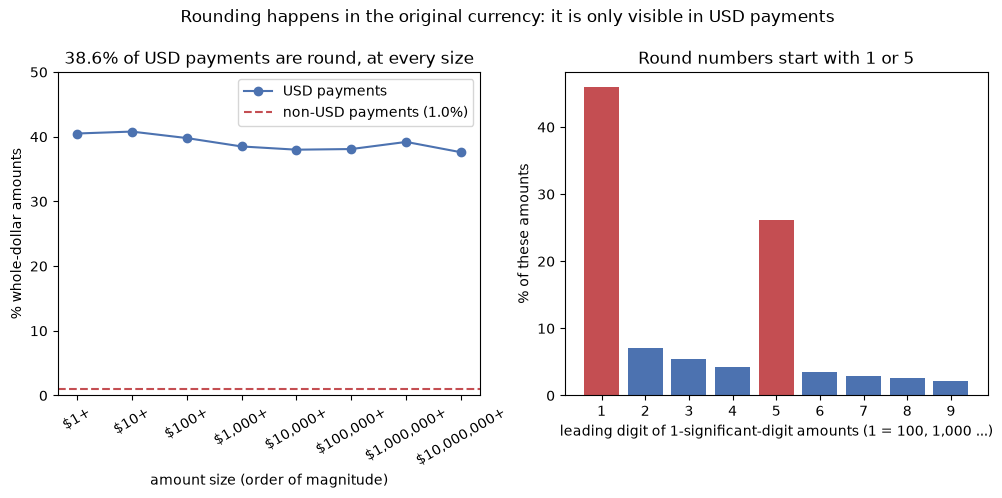

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
t = m6.assign(k=m6.pct_whole_dollars * m6.n).groupby("is_usd")[["k", "n"]].sum()
w = t.k / t.n   # % whole-dollar amounts, weighted by number of payments
axes[0].plot(m6_size.magnitude, m6_size.pct_whole_dollars, marker="o", color="#4C72B0", label="USD payments")
axes[0].axhline(w[False], color="#C44E52", ls="--", label=f"non-USD payments ({w[False]:.1f}%)")
axes[0].set_ylim(0, 50)
axes[0].set_xticks(m6_size.magnitude)
axes[0].set_xticklabels([f"\\${10 ** m:,}+" for m in m6_size.magnitude], rotation=30)
axes[0].set_xlabel("amount size (order of magnitude)")
axes[0].set_ylabel("% whole-dollar amounts")
axes[0].legend()
axes[0].set_title(f"{w[True]:.1f}% of USD payments are round, at every size")
lead = m6_lead.set_index("leading_digit").n
axes[1].bar(lead.index, lead / lead.sum() * 100, color=["#C44E52" if d in (1, 5) else "#4C72B0" for d in lead.index])
axes[1].set_xticks(range(1, 10))
axes[1].set_xlabel("leading digit of 1-significant-digit amounts (1 = 100, 1,000 ...)")
axes[1].set_ylabel("% of these amounts")
axes[1].set_title("Round numbers start with 1 or 5")
fig.suptitle("Rounding happens in the original currency: it is only visible in USD payments", y=1.03)
save(fig, "M6_round_amounts")
plt.show()

## M7. Route vs amount (H-M7)
Level by transaction type and by number of banks, after removing the party-pair mean and the sender-country level.

In [16]:
m7 = q("""
    WITH m AS (SELECT party_pair, sender_country, avg(usd_amount_log10) AS m FROM normal GROUP BY 1, 2)
    SELECT 'transaction type' AS dimension, transaction_type_code AS value, count(*) AS n,
           avg(usd_amount_log10) AS raw_mean_log10, avg(usd_amount_log10 - m.m) AS level_after_country_and_pair
    FROM normal JOIN m USING (party_pair, sender_country) GROUP BY 2
    UNION ALL
    SELECT 'banks in route', CAST(least(participant_count, 6) AS VARCHAR), count(*),
           avg(usd_amount_log10), avg(usd_amount_log10 - m.m)
    FROM normal JOIN m USING (party_pair, sender_country) GROUP BY 2
    ORDER BY 1, 2
""")
m7.round(3)  # "6" = 6 or more banks

,dimension,value,n,raw_mean_log10,level_after_country_and_pair
0,banks in route,2,6318885,3.543,0.000
1,banks in route,3,2322649,3.544,0.000
2,banks in route,4,854759,3.544,-0.002
3,banks in route,5,313790,3.542,-0.000
4,banks in route,6,182911,3.543,-0.003
5,transaction type,Covered,415815,3.603,0.013
6,transaction type,Direct,6318885,3.543,0.000
7,transaction type,Indirect,3258294,3.536,-0.002


## M8. Results → rules (verified on all 9,992,994 normal payments)

| ID | Rule (condition → effect → size → rows covered) | Evidence | Confidence |
|---|---|---|---|
| R-M1 | Every amount is drawn from a **log-normal** distribution: `log10(amount)` is a bell curve with the **same spread for all four party pairs** (SD 0.99-1.00, skewness -0.12 to -0.13, excess kurtosis 0.08-0.15). Medians: C2C **\$464**, B2C **\$3,118**, C2B **\$3,236**, B2B **\$22,883**. | M1 | High |
| R-M2 | Party types act **additively on the log scale**: a business **sender** multiplies the amount by **6.9x** (+0.839) and a business **receiver** by **7.1x** (+0.853). Predicted B2B = 49x C2C, observed 51x (difference 0.017 log10). The receiver effect also holds **within the same sender** (+0.83 for business senders, +0.80 for consumer senders). | M2 | High |
| R-M3 | Each sender account has **its own amount level**: the sender explains **25.2%** of the variance of log10(amount). Sender means vary with SD **0.44** (businesses) and **0.38** (consumers), 4x more than pure noise would give (0.09-0.10). | M3 | High |
| R-M4 | The **sender's country** sets a level on top of that: country levels vary with SD **0.47** log10 (62 countries with 20k+ payments; e.g. Luxembourg **3.3x**, US **2.0x**, China **0.3x** the average). The **receiver's country** has a much smaller effect (SD **0.10**). | M4 | High |
| R-M5 | The **currency has no effect of its own**: currency levels vary with SD 0.435 before, but only **0.002 after** removing the sender-country level. Payments in a currency other than the sender's home currency (1.05M rows) have the same level as home-currency payments (-0.002 vs 0.000). The apparent currency differences come entirely from who sends them. | M5 | High |
| R-M6 | **38.6%** of USD payments are **whole-dollar amounts**, the same at every size (37.6-40.8% from \$1 to \$10M), for business and consumer senders, inside and outside the US (38.0-38.7%). Non-USD payments show **1.0%**, exactly what random cents give, so rounding happens in the **original currency** before conversion. Businesses round to larger units (12.7% / 10.5% exact thousands vs 7.7% / 5.8% for consumers). Round amounts start with **1 (46%) or 5 (26%)**; the most common USD amounts are \$10,000, \$1,000 and \$5,000. | M6 | High (USD) / Medium (other currencies: inferred, not visible) |
| R-M7 | The **route does not depend on the amount**: with country and party pair removed, every route type and every number of banks (2 to 6+) is within ±0.013 log10 of 0. | M7 | High |

**Hypotheses that did not hold:**
- H-M5 "the currency has its own effect": rejected (0.002 after the sender country is removed).
- H-M7 "larger payments use longer routes": rejected. Covered payments look 15% larger in the raw data (3.603 vs 3.543), but the gap disappears once sender country and party pair are removed (+0.013), so it is a **country-mix effect**, not a routing rule.
- H-M4 for the **receiver** side: the receiver's country adds little (SD 0.10 vs 0.47 for the sender).
- H-M1 holds only approximately: log10(amount) has a slight negative skew (-0.12), plus spikes at round numbers from R-M6.

**Still unexplained / limits:** how each country's level was chosen. The brief says country sizes and economies are randomised, so the levels should not be read as real-world wealth. Rounding in non-USD currencies cannot be measured because the original amount is not in the data.